# Loop Research · StockNet 小规模实验日志

## tl;dr

2026-10-15 完成 50 股、306 次尝试；E0–E3 均为 **0 入库**。40 次 DeepSeek‑V4.1‑Flash 调用共 32,316 tokens，按官方高峰价与缓存用量估算 **¥0.103**，账户余额差额约 ¥0.10；费用保守上界 **¥0.259**，授权上限 ¥40。

未放宽门槛；没有获准因子，测试期没有可评估的因子组合。以下只解释开发期过程与失败结果。

本 notebook **只读取已归档结果，不发起模型调用**。


## Context & Methods

搜索期 2012-09-04–2013-12-31；筛选期 2014–2015；封存测试期 2016-01-01–2017-09-01。

### Key Assumptions

- 股票池只按搜索期质量选取，并按 ticker 稳定排序取前 50；所有分支使用 seed 42。
- 预热 120 个交易日；5 日标签从 t+1 开盘到 t+6 开盘，搜索期末 6 天标签保持缺失。
- 收盘信号、次日开盘成交，前 20% 等权做多，每 5 日调仓；单边成本 0.1%，策略与基准均计费并平仓。
- 信号方向在搜索期确定后冻结；11 项门槛不随结果改变。筛选期属于反复使用的开发数据。
- StockNet 股票池有事后选样偏差，历史复权不是 point-in-time 数据；LLM 可能接触过公开历史行情。重叠标签不用于 IID 显著性结论。

来源：[固定 StockNet 版本](https://github.com/yumoxu/stocknet-dataset/tree/330708b5ddc359961078bef469f43f48992fd6e4/price/raw)；[DeepSeek 官方定价](https://api-docs.deepseek.com/zh-cn/quick_start/pricing)。


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT = Path.cwd()
EXPERIMENT = ROOT / "artifacts/stocknet_flash_20261015_v1"
REPORT = json.loads((EXPERIMENT / "report.json").read_text())
MANIFEST = json.loads((EXPERIMENT / "data_manifest.json").read_text())
AUDIT = json.loads((EXPERIMENT / "verification.json").read_text())
FIGURES = EXPERIMENT / "figures"
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 130,
                    "font.size": 11, "axes.spines.top": False,
                    "axes.spines.right": False, "axes.grid": False,
                    "savefig.facecolor": "white"})
assert REPORT["status"] == "completed" and AUDIT["status"] == "passed"
assert REPORT["budget"]["run_cost_upper_bound_cny"] < 40


## Data

固定源仓库 commit 和 88 个源文件校验和均在 `data_manifest.json`。50 股共有 62,900 行、1,258 个交易日，冻结股票池无缺失交易日，无复权收盘价单日绝对涨跌超过 50% 的记录。OHLC 统一乘以 `Adj Close / Close`，成交量不缩放，不填补缺失。

下表仅显示安全的源数据预览与版本。

In [2]:
print("Commit:", MANIFEST["commit"])
print("Processed SHA-256:", MANIFEST["processed_sha256"])
print("Symbols:", ", ".join(MANIFEST["symbols"]))
print("Missing market-calendar rows:", sum(MANIFEST["quality"]["missing_calendar_rows"].values()))
prices = pd.read_csv(ROOT / "data/stocknet-330708b5/prices.csv.gz")
display(prices[["date", "symbol", "open", "high", "low", "close", "volume"]].head().round(4))


Commit: 330708b5ddc359961078bef469f43f48992fd6e4
Processed SHA-256: f88cea3c3bbd6c2d0aff9e6473f9795350b972d6407baad1cab58a912f6ac61a
Symbols: AAPL, ABB, AEP, AMGN, AMZN, BA, BAC, BBL, BCH, BHP, BP, BRK-A, BSAC, BUD, C, CAT, CELG, CHL, CHTR, CMCSA, CODI, CSCO, CVX, D, DHR, DIS, DUK, EXC, FB, GD, GE, GOOG, HD, HON, HRG, HSBC, IEP, INTC, JNJ, JPM, KO, LMT, MA, MCD, MDT, MMM, MO, MRK, MSFT, NEE
Missing market-calendar rows: 0


,date,symbol,open,high,low,close,volume
0,2012-09-04,AAPL,85.9324,87.1431,85.7697,87.1211,91973000
1,2012-09-04,ABB,14.5534,14.5785,14.3855,14.4694,1474300
2,2012-09-04,AEP,35.5482,35.7549,35.4077,35.6640,2068800
3,2012-09-04,AMGN,75.1862,75.9039,74.8004,75.6617,3719200
4,2012-09-04,AMZN,248.2700,251.0000,244.6600,247.8800,3950800


## Results

### 1. 四组尝试与筛选

E1 的随机搜索与 E2 是整体方案对照。E2/E3 使用相同初始 seed，但模型输出、父代和搜索轨迹会分叉，单次对比只作描述。

,attempts,legal,backtested,accepted,unique_expressions,unique_skeletons
E0,6,6,6,0,6,6
E1,100,100,97,0,97,82
E2,100,79,57,0,72,56
E3,100,79,57,0,69,56


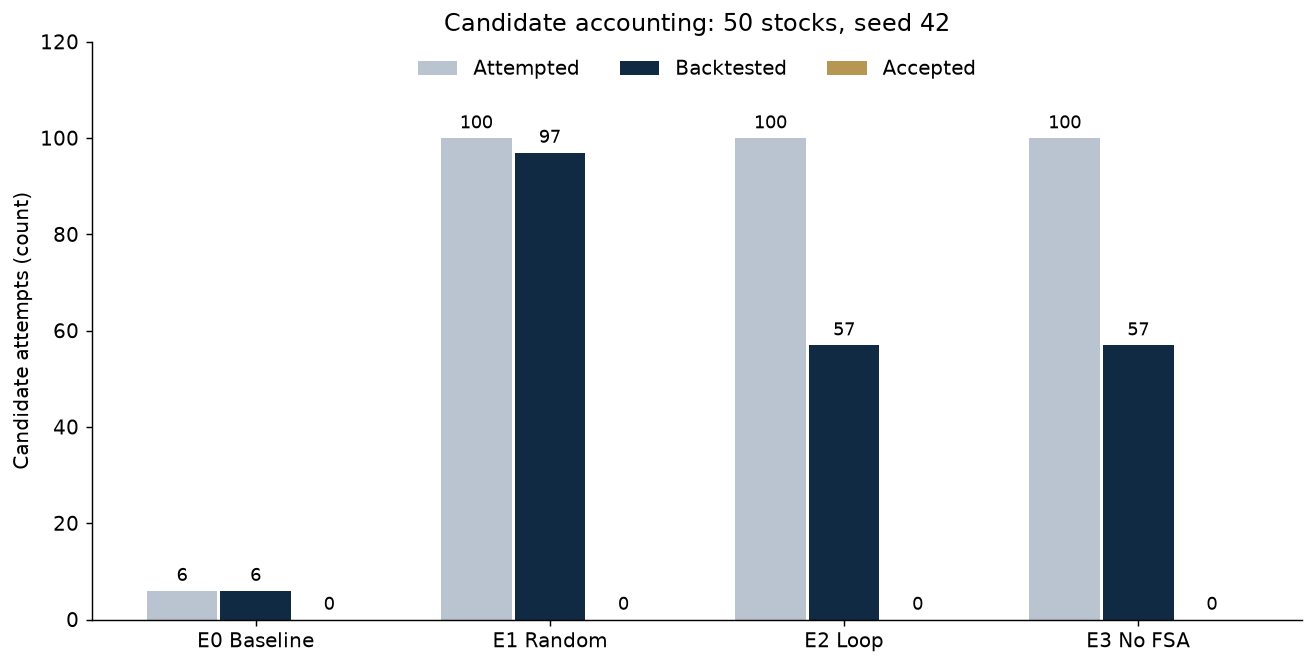

In [3]:
columns = ["attempts", "legal", "backtested", "accepted", "unique_expressions", "unique_skeletons"]
counts = pd.DataFrame({k: {c: v[c] for c in columns} for k, v in REPORT["branches"].items()}).T
display(counts)
fig, ax = plt.subplots(layout="constrained")
x = np.arange(len(counts))
for offset, key, color, label in [(-.25, "attempts", "#b9c4d0", "Attempted"),
                                (0, "backtested", "#102a43", "Backtested"),
                                (.25, "accepted", "#b79552", "Accepted")]:
    bars = ax.bar(x + offset, counts[key], width=.24, color=color, label=label)
    ax.bar_label(bars, padding=3, fontsize=10)
ax.set(xticks=x, xticklabels=["E0 Baseline", "E1 Random", "E2 Loop", "E3 No FSA"],
       ylim=(0, 120), ylabel="Candidate attempts (count)",
       title="Candidate accounting: 50 stocks, seed 42")
ax.legend(ncol=3, frameon=False, loc="upper center")
fig.savefig(FIGURES / "candidate-accounting.png", bbox_inches="tight")
plt.show()


实际回测合计 217 次；E2 另有 7 次因 FSA 被拒绝。四组均无入库，不能据此证明 Loop 优于随机搜索或 FSA 改善收益。

### 2. 基线交易成本

下图是 **2014–2015 筛选期** 的相对年化收益，不是独立测试表现。成本前与成本后分别使用对应成本口径的等权基准。

,Factor,Frozen direction,Discovery Rank IC,Gross annual excess (%),Net annual excess (%)
0,20d momentum,1,0.0325,-2.3944,-6.2572
1,5d reversal,1,0.0155,-1.7261,-9.0249
2,Low volatility,-1,0.0291,-6.8598,-9.0653
3,Overnight gap,1,0.0067,-0.8548,-7.9331
4,Intraday pressure,-1,0.0222,2.0482,-5.6347
5,Price/volume,-1,0.0374,-1.4995,-5.2678


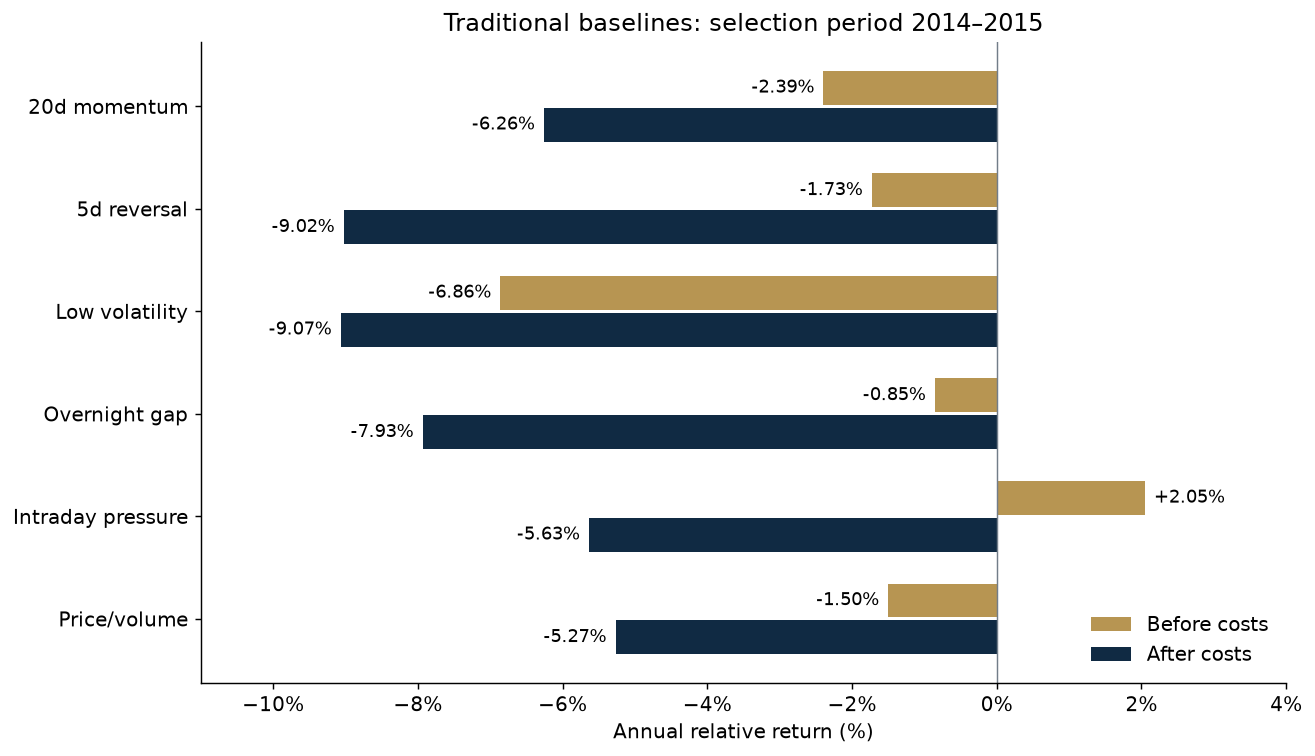

In [4]:
baseline = json.loads((EXPERIMENT / "E0/candidates.json").read_text())
names = ["20d momentum", "5d reversal", "Low volatility", "Overnight gap", "Intraday pressure", "Price/volume"]
gross = np.array([f["periods"]["selection_gross"]["annual_excess"] for f in baseline]) * 100
net = np.array([f["periods"]["selection"]["annual_excess"] for f in baseline]) * 100
display(pd.DataFrame({"Factor": names, "Frozen direction": [f["direction"] for f in baseline],
                      "Discovery Rank IC": [f["discovery_ic"] for f in baseline],
                      "Gross annual excess (%)": gross, "Net annual excess (%)": net}).round(4))
fig, ax = plt.subplots(figsize=(10, 5.7), layout="constrained")
y = np.arange(len(names))
for offset, values, color, label in [(-.18, gross, "#b79552", "Before costs"),
                                   (.18, net, "#102a43", "After costs")]:
    bars = ax.barh(y + offset, values, height=.33, color=color, label=label)
    ax.bar_label(bars, labels=[f"{v:+.2f}%" for v in values], padding=5, fontsize=10)
ax.set(yticks=y, yticklabels=names, xlim=(-11, 4), xlabel="Annual relative return (%)",
       title="Traditional baselines: selection period 2014–2015")
ax.invert_yaxis()
ax.axvline(0, color="#727d89", linewidth=.8)
ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.legend(frameon=False, loc="lower right")
fig.savefig(FIGURES / "baseline-costs.png", bbox_inches="tight")
plt.show()


只有日内压力基线在成本前有正的相对年化收益（约 +2.05%），成本后变为约 −5.63%。六个固定基线在固定方向和成本口径下均未入库。这不能外推到其他股票池或当前市场。

### 3. 拒绝原因、预算与独立复核

In [5]:
failures = pd.DataFrame({k: v["gate_failures"] for k, v in REPORT["branches"].items()}).fillna(0).astype(int)
display(failures)
display(pd.DataFrame([{
    "Model calls": AUDIT["archived_calls"], "Tokens": AUDIT["tokens"],
    "Estimated charge CNY (peak prices)": AUDIT["peak_price_usage_estimate_cny"],
    "Conservative upper bound CNY": REPORT["budget"]["run_cost_upper_bound_cny"],
    "IC max absolute error vs SciPy": AUDIT["max_ic_absolute_error"],
    "NAV max absolute error vs scalar ledger": AUDIT["max_nav_absolute_error"]}]))
assert sum(v["accepted"] for v in REPORT["branches"].values()) == 0
assert all(v["composite"] is None for v in REPORT["holdout"].values())
assert AUDIT["max_ic_absolute_error"] < 1e-10
assert AUDIT["max_nav_absolute_error"] < 1e-10
print("Verified: no approved factor, no synthetic holdout composite, budget below CNY 40.")


,E0,E1,E2,E3
G02,6,80,44,48
G03,6,83,48,47
G04,6,90,50,49
G05,6,91,51,48
G06,6,97,57,57
G07,6,78,42,40
G08,6,83,48,47
G01,4,86,44,36
G11,0,1,0,2


,Model calls,Tokens,Estimated charge CNY (peak prices),Conservative upper bound CNY,IC max absolute error vs SciPy,NAV max absolute error vs scalar ledger
0,40,32316,0.102799,0.258528,4.994338e-13,4.999778e-12


Verified: no approved factor, no synthetic holdout composite, budget below CNY 40.


## Takeaways

- 306 次候选尝试的过程完整，217 次实际回测均未超过固定的 Calmar > 1 门槛，0 入库是本次有效结果。
- 账户余额差额约 ¥0.10；40 次调用的 usage 估算约 ¥0.103，保守上界 ¥0.259。预算账本保留在 `artifacts/budgets/deepseek.sqlite3`。
- 已将归档响应完整回放，未新增模型请求；每次请求的角色、提示词 hash、模型版本、usage 和简短输出可在 `calls/` 检查，不保存隐藏推理或凭据。
- 数据、代码与规则版本分别保存在 `data_manifest.json`、`source_snapshot.zip`、`config.json` 和 `freeze.json`。同一历史区间上的后续迭代应标为探索性。
- 本实验验证工程流程，不证明可交易 Alpha；没有通过筛选的因子，故未构造测试期组合。

复跑本 notebook 只需读取原始产物；完整响应回放命令见仓库 README。